<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_2_Regression/Projects/Instructions/Project.2-Housing/Housing-Pass-17a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2 - Pass 17a: Housing Price Prediction






The project should be done using Regression prediction techniques ( with feature scaling and regularization ) as covered in class.
The goal is to minimize the RMS ***percentage*** error ( root mean squared percentage error - RMSPE ) on your prediction of the house sales price.



Any of the available features can be used in the regression, but a minimum set of variables that do the job should be the ultimate goal.



Be sure to go through the whole data science process and document as such in your Jupyter notebook.



This project will have less direct "To Do" guidance and the progression through the data science process will be more individualized this time around.  We will talk about all the issues during class so you're not going to be out on a ledge with this one, I just want to move you towards performing a data science project on your own eventually.

There are two parts to this data set, both of which are on AWS:

- [Housing Data Dictionary]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Housing%20-%20Data%20Documentation.pdf )
- [Data Set]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv)


In [1]:
! curl -s -I https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv

HTTP/1.1 200 OK
x-amz-id-2: xzzAXEtr1WwfuZXzJ1nkf9lOsRNdxkAhcAk7+p94wrwAKBiEnuP12YEPX/w/wCOgl/WsONBeZXTbA5fiDbzznjydch5uHaNQ
x-amz-request-id: 10MABMNHFN12VT4D
Server: AmazonS3
Date: Wed, 04 Nov 2026 15:14:31 GMT
Last-Modified: Fri, 06 Oct 2023 04:00:27 GMT
ETag: "76e84c9ee7f6fd4d51276697f81e76e1"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 880420
Content-Type: text/csv



In [2]:
! curl -s https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv | head -2

PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
905101070,20,RL,62.0,14299,Pave,,Reg,Lvl,AllPub,Inside,G

## Problem Definition

### Business Problem

Help investors evaluate whether what features might be a useful factor when assessing a property's potential market value.

### Data Science Problem

Supervised regression

## Data Collection/Sources

### Load Modules

In [3]:
# Import the libraries and modules
from IPython.display import Image

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import statsmodels.api as sm

from sklearn import datasets, metrics, model_selection
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

### Load Data

In [4]:
# Define the data's url as 'url'
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [5]:
# Define the data frame as 'df'
df = pd.read_csv(url)

## Data Cleaning

### Overview

In [6]:
# Display the head - 81 columns
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


In [7]:
# Display the tail - target is the last row
df.tail()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,528292060,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


In [8]:
# See the shape - 2637 rows, 81 columns
df.shape

(2637, 81)

In [9]:
# See how many total entries
df.size

213597

### Summary Statistics

Summary statistics give you a quick overview of the data.  Some items to spot check:
- the Target:
  - look for nulls
    - null will be culled
  - look at min, max, median, and mean
    - is it a categorical field masquerading as a number?
- the Features:
  - numerical
    - look at min, max, median, and mean
      - a min=1 and max=count suggests an ID
  - categorical
    - look at unique and freq
      - freq=1, unique=count suggests an ID
      - freq=count suggests a meaningless feature

In [10]:
# Summary meta-data - our target 'SalePrice' is int64, our feature 'Lot Frontage' is float64
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2637 non-null   int64  
 1   MS SubClass      2637 non-null   int64  
 2   MS Zoning        2637 non-null   object 
 3   Lot Frontage     2188 non-null   float64
 4   Lot Area         2637 non-null   int64  
 5   Street           2637 non-null   object 
 6   Alley            180 non-null    object 
 7   Lot Shape        2637 non-null   object 
 8   Land Contour     2637 non-null   object 
 9   Utilities        2637 non-null   object 
 10  Lot Config       2637 non-null   object 
 11  Land Slope       2637 non-null   object 
 12  Neighborhood     2637 non-null   object 
 13  Condition 1      2637 non-null   object 
 14  Condition 2      2637 non-null   object 
 15  Bldg Type        2637 non-null   object 
 16  House Style      2637 non-null   object 
 17  Overall Qual  

In [11]:
# See the summary statistics
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
PID,2637.0,7.141301e+08,1.887527e+08,526301100.0,5.284770e+08,535453040.0,9.071870e+08,1.007100e+09
MS SubClass,2637.0,5.734926e+01,4.249909e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2188.0,6.916682e+01,2.335678e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2637.0,1.004469e+04,6.742550e+03,1300.0,7.436000e+03,9450.0,1.152600e+04,1.646600e+05
Overall Qual,2637.0,6.097459e+00,1.411522e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2637.0,5.569966e+00,1.118262e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2637.0,1.971289e+03,3.030699e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2637.0,1.984203e+03,2.091308e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2614.0,1.018879e+02,1.795782e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03
BsmtFin SF 1,2636.0,4.384412e+02,4.496023e+02,0.0,0.000000e+00,368.0,7.320000e+02,5.644000e+03


### Nulls & Identifier Columns

#### Target Nulls


The target should be the first field that you look at.  Its data type will tell you what kind of machine learning problem this is ( classification or regression. ) Any nulls should be culled.  You can check for any skew in the data set.

In [12]:
# Define the name of the target column 'SalePrice' to work with it independently
target_col = 'SalePrice'
df[target_col]

,SalePrice
0,115400
1,90000
2,141000
3,254000
4,155000
...,...
2632,114500
2633,162000
2634,211500
2635,165000


In [13]:
# Look for nulls in the target 'SalePrice' (dropping rows if 20% nulls or under) - no nulls in the target
df[target_col].isnull().sum() / df[target_col].shape[0] * 100


np.float64(0.0)

#### Feature Nulls

In [14]:
# Define the name of the feature columns to work with them independently

# Drop the target column from the feature column names
feature_cols = df.drop(columns=target_col, errors='ignore')

feature_cols.dtypes

,0
PID,int64
MS SubClass,int64
MS Zoning,object
Lot Frontage,float64
Lot Area,int64
...,...
Misc Val,int64
Mo Sold,int64
Yr Sold,int64
Sale Type,object


In [15]:
# Look for nulls in the features
(feature_cols.isnull().sum() / feature_cols.shape[0] * 100).sort_values(ascending=False)

,0
Pool QC,99.582859
Misc Feature,96.359499
Alley,93.174061
Fence,79.977247
Mas Vnr Type,60.940463
...,...
Misc Val,0.000000
Mo Sold,0.000000
Yr Sold,0.000000
Sale Type,0.000000


In [16]:
feature_cols

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,Shed,500,10,2006,WD,Normal
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,126,0,NaN,NaN,NaN,0,12,2007,WD,Normal
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,7,2009,WD,Normal
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,9,2009,WD,Normal
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal


#### Identifier Columns

In [17]:
# See proportion of unique values in the target column
(df[target_col].nunique() / df[target_col].shape[0] * 100) #.sort_values(ascending=False)

37.2772089495639

In [18]:
# See proportion of unique values in the feature columns - highest is 1%
(feature_cols.nunique() / feature_cols.shape[0] * 100).sort_values(ascending=False)

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
Bsmt Unf SF,40.955631
1st Flr SF,38.756162
...,...
Garage Finish,0.113766
Paved Drive,0.113766
Alley,0.075844
Street,0.075844


### Backup #1

In [19]:
# Make a backup
df_bak1 = df.copy()

In [20]:
# Restore from backup
df = df_bak1.copy()

### Cull the Nulls

If equal to or greater than 90%, dropped columns.

If between 20-89%, imputed with the mode.

If between 0-19%, dropped the rows.

In [21]:
# Calculate the percentage of nulls in each feature column
null_percent = (feature_cols.isnull().sum() / df.shape[0] * 100).sort_values(ascending=False)

null_percent

,0
Pool QC,99.582859
Misc Feature,96.359499
Alley,93.174061
Fence,79.977247
Mas Vnr Type,60.940463
...,...
Misc Val,0.000000
Mo Sold,0.000000
Yr Sold,0.000000
Sale Type,0.000000


Drop Columns

In [22]:
# Identify columns with 90% or greater nulls
cols_to_drop = null_percent[null_percent >= 90].index

In [23]:
# Rebuild feature_cols, keeping only columns below 90% nulls
feature_cols = [col for col in feature_cols if col not in cols_to_drop]

In [24]:
# Check the number of remaining features
print("Number of feature columns AFTER:", len(feature_cols))

Number of feature columns AFTER: 77


Impute

In [25]:
# Identify feature columns containing 40%-80% nulls
cols_to_impute = null_percent[
    (null_percent >= 20) & (null_percent <= 89)
].index.intersection(feature_cols)

# Impute nulls based on data type
for col in cols_to_impute:

    # Categorical features: impute with mode
    if df[col].dtype == 'object':
        df[col] = df[col].fillna(df[col].mode()[0])

    # Numeric features (integers and floats): impute with median
    elif pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())

# Update feature_cols to include only the columns that still exist in df
feature_cols = df[feature_cols].columns

In [26]:
# Check the number of remaining features
print("Number of feature columns AFTER:", len(feature_cols))

Number of feature columns AFTER: 77


Drop Rows

In [27]:
# Verify the shape before dropping rows
df[feature_cols].shape

(2637, 77)

In [28]:
# Identify feature columns containing 0%-19% nulls
cols_to_drop_rows = null_percent[
    (null_percent > 0) & (null_percent <= 19)
].index.intersection(feature_cols)

# Drop rows containing nulls in those feature columns
df = df.dropna(subset=cols_to_drop_rows).reset_index(drop=True)

# Update feature_cols to reflect the remaining columns
feature_cols = [col for col in feature_cols if col in df.columns]

In [29]:
# Verify rows dropped
df[feature_cols].shape

(1984, 77)

In [30]:
# Verify no nulls in feature columns
df[feature_cols].isnull().sum().sort_values(ascending=False)

,0
PID,0
MS SubClass,0
MS Zoning,0
Lot Frontage,0
Lot Area,0
...,...
Misc Val,0
Mo Sold,0
Yr Sold,0
Sale Type,0


### Backup #2

In [31]:
# Make a backup
df_bak2 = df.copy()

In [32]:
# Restore from backup
df = df_bak2.copy()

### Drop Identifier Column

In [33]:
# Drop the identifier column 'PID'
id_col = 'PID'

feature_cols = [col for col in feature_cols if col != id_col]

In [34]:
# Verify identifier column dropped
df[feature_cols].shape

(1984, 76)

### Backup #3

In [35]:
# Make a backup
df_bak3 = df.copy()

In [36]:
# Restore from backup
df = df_bak3.copy()

### Cleaned Data Frame

In [37]:
# Define our target and feature columns as a data frame to work with 'df_clean'
df_clean = pd.concat([df[target_col], df[feature_cols]], axis=1).reset_index(drop=True)

In [38]:
# Verify the working data frame
df_clean

,SalePrice,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Lot Shape,Land Contour,Utilities,Lot Config,...,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Fence,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition
0,115400,20,RL,62.0,14299,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,MnPrv,0,7,2007,WD,Normal
1,141000,50,RM,50.0,9000,Pave,Reg,Bnk,AllPub,Inside,...,0,0,126,0,MnPrv,0,12,2007,WD,Normal
2,254000,60,FV,68.0,7379,Pave,IR1,Lvl,AllPub,Inside,...,0,0,0,0,MnPrv,0,4,2010,WD,Normal
3,155000,70,RL,60.0,7200,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,MnPrv,0,4,2009,WD,Normal
4,125000,20,RL,70.0,8521,Pave,Reg,Lvl,AllPub,FR2,...,0,0,0,0,MnPrv,0,5,2010,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1979,114500,50,RM,52.0,6240,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,MnPrv,400,9,2006,WD,Normal
1980,162000,80,RL,74.0,10778,Pave,IR1,Lvl,AllPub,Inside,...,0,0,0,0,MnPrv,0,7,2009,WD,Normal
1981,211500,120,RL,61.0,3782,Pave,IR1,Lvl,AllPub,CulDSac,...,0,0,0,0,MnPrv,0,9,2009,WD,Normal
1982,165000,20,RL,78.0,10140,Pave,Reg,Lvl,AllPub,Inside,...,0,0,0,0,MnPrv,0,8,2009,WD,Normal


## EDA (Exploratory Data Analysis)

### Feature Selection

One-hot encode the dataset. Then scale and perform feature selection.



In [39]:
# Convert categorical features into numeric columns
X_all_features = pd.get_dummies(df_clean[feature_cols], drop_first=True, dtype=int)

# Define the target
y_target = df_clean[target_col]

In [40]:
# Specify values of alpha we want to try
alpha = [50, 75, 100, 200, 300, ]

# Create empty list to hold results
results_alpha = []

for a in alpha:
  # Calculate CV RMSE
  n = 200
  results = np.zeros(n)

  for idx in range(n):
    # Train, test split
    X_train, X_test, y_train, y_test = train_test_split(X_all_features, y_target, test_size=0.25)

    # Standard scale only training features
    scaler = StandardScaler()
    scaler.fit(X_train)
    X_train_scaled = scaler.transform(X_train)

    # Scale testing features
    X_test_scaled = scaler.transform(X_test)

    # Create the model
    model_ridge = Ridge(alpha = a, tol = .01, max_iter=10_000); # Looping through alpha

    # Fit regression
    model_ridge.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model_ridge.predict(X_test_scaled)

    # Calculate and record performance metric
    results[idx] = np.sqrt(mean_squared_error(y_test,y_pred))

  results_alpha.append(results.mean())

results_df = pd.DataFrame({'Alpha': alpha, 'RMSE': results_alpha})


In [41]:
results_df.sort_values( by = 'RMSE' )


,Alpha,RMSE
3,200,29965.928841
0,50,29972.350162
4,300,30306.594385
2,100,30552.962526
1,75,31275.553875


Get the Alpha that results in the highest RMSE.

In [42]:
results_df.sort_values( by = 'RMSE' )["Alpha"].iloc[0]


np.int64(200)

In [43]:
a = results_df.sort_values( by = 'RMSE' )["Alpha"].iloc[0]
a

np.int64(200)

In [44]:
# %%capture --no-stdout
# Perform CV
n = 200
results = np.zeros(n)

for idx in range(n):
  # Train, test split
  X_train, X_test, y_train, y_test = train_test_split(X_all_features, y_target, test_size=0.25)

  # Standard scale only training features
  scaler = StandardScaler()
  scaler.fit(X_train)
  X_train_scaled = scaler.transform(X_train)

  # Scale testing features
  X_test_scaled = scaler.transform(X_test)

  # Create the model
  model_ridge = Ridge(alpha = a, tol = .01, max_iter=10000)

  # Fit regression
  model_ridge.fit(X_train, y_train)

  # Predict
  y_pred = model_ridge.predict(X_test)

  # Calculate and record performance metric
  results[idx] = np.sqrt(mean_squared_error(y_test,y_pred))

print(f"CV RMSE: {results.mean().round(2)}")
print(f"Number of Predictors: {sum(model_ridge.coef_ >0)}")

CV RMSE: 32099.51
Number of Predictors: 106


In [45]:
X_all_features.shape

(1984, 235)

In [46]:
len(X_all_features.columns)

235

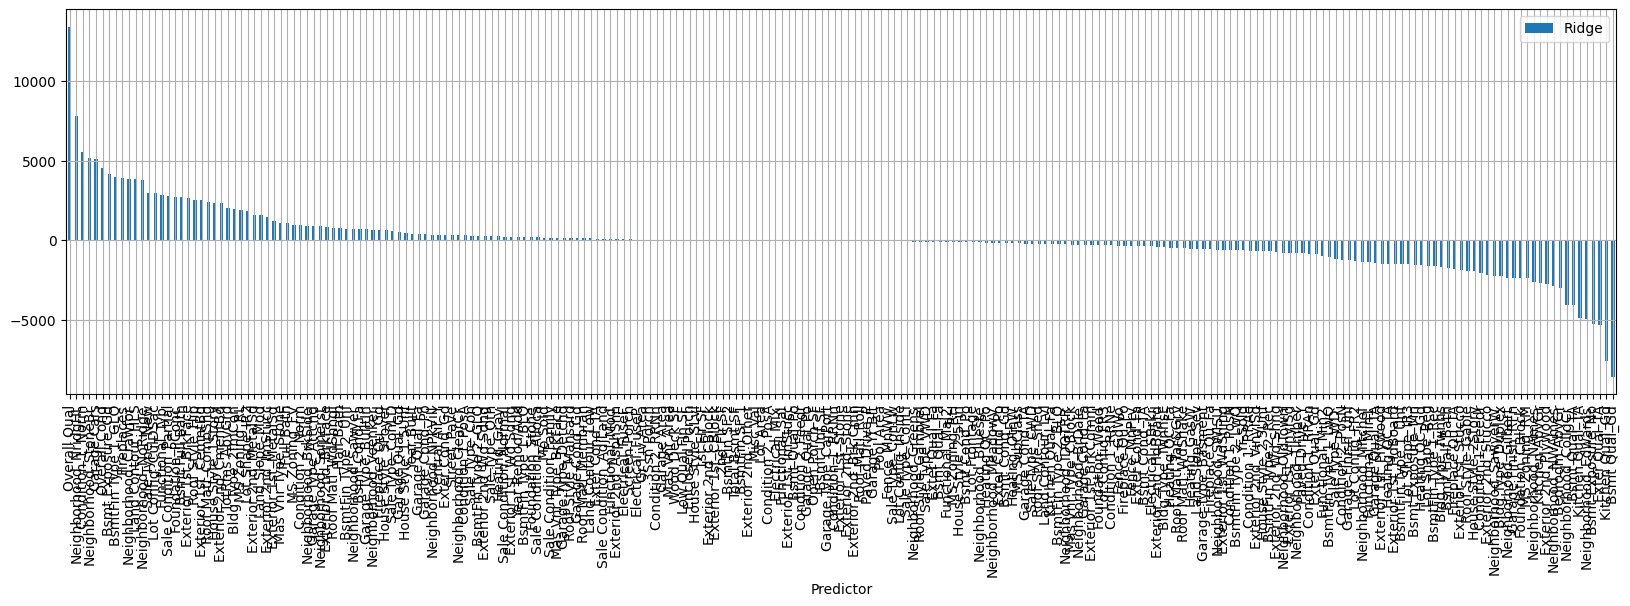

In [47]:
# Plot model coefficients
model_results = pd.DataFrame()
model_results['Predictor'] = X_all_features.columns
model_results['Ridge'] = model_ridge.coef_
model_results.sort_values( by = ["Ridge"], ascending = False ).plot(
    x = 'Predictor',
    kind = 'bar',
    figsize = (20,5)
    )
plt.grid()

In [48]:
model_results['Ridge'].abs().sort_values()

,Ridge
118,0.000000
88,0.000000
186,0.000000
157,0.000000
195,0.000000
...,...
79,5547.757312
189,7620.203359
69,7845.547298
156,8598.022625


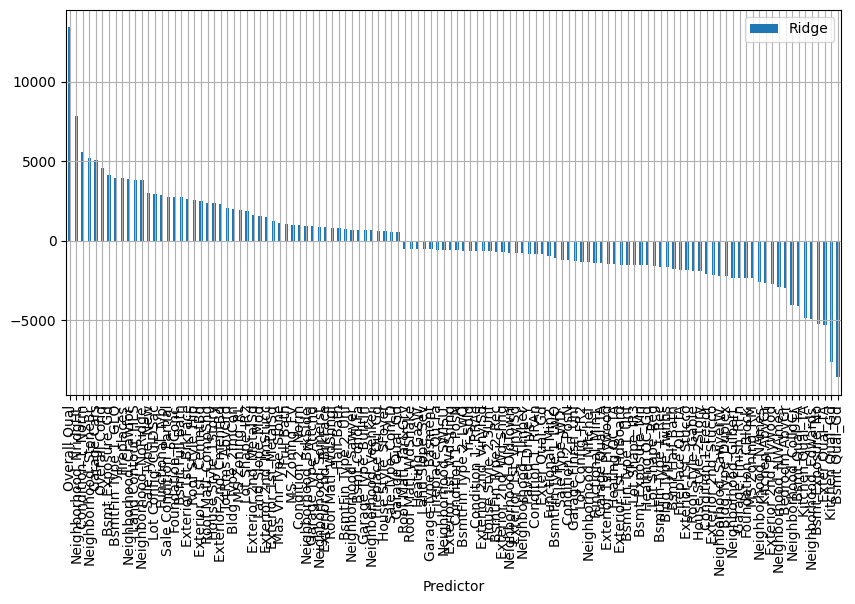

In [49]:
# Plot parameters with coefficients greater than 0
greater_0 = model_results[(model_results['Ridge'] > 500 ) | (model_results['Ridge'] < -500 )]
greater_0.sort_values( by = ["Ridge"], ascending = False ).plot(x = 'Predictor', kind = 'bar', figsize = (10,5))
plt.grid()

In [50]:
X_features_work = X_all_features[greater_0["Predictor"]]

### Working Data Frame

In [51]:
df_work = pd.concat([df_clean[target_col], X_features_work], axis=1).reset_index(drop=True)

In [52]:
df_work

,SalePrice,Overall Qual,Overall Cond,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,TotRms AbvGrd,...,Garage Type_BuiltIn,Garage Finish_RFn,Garage Finish_Unf,Garage Qual_Gd,Garage Qual_TA,Paved Drive_Y,Sale Type_ConLD,Sale Type_New,Sale Type_WD,Sale Condition_Partial
0,115400,4,3,1.0,0.0,1,0,3,1,5,...,0,0,1,0,1,0,0,0,1,0
1,141000,6,6,0.0,0.0,1,1,3,1,6,...,0,0,1,0,1,0,0,0,1,0
2,254000,8,5,1.0,0.0,2,1,3,1,7,...,0,1,0,0,1,1,0,0,1,0
3,155000,7,9,1.0,0.0,1,0,3,1,6,...,0,1,0,0,1,1,0,0,1,0
4,125000,5,5,0.0,0.0,1,0,3,1,5,...,0,0,1,0,1,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1979,114500,6,6,0.0,0.0,1,0,3,1,6,...,0,0,1,0,1,1,0,0,1,0
1980,162000,7,6,1.0,0.0,1,1,1,1,4,...,0,0,1,0,1,1,0,0,1,0
1981,211500,8,5,1.0,0.0,1,0,1,1,4,...,0,0,0,0,1,1,0,0,1,0
1982,165000,6,5,0.0,0.0,2,0,3,1,7,...,0,1,0,0,1,1,0,0,1,0


## Push Parquet to Hugging Face

### Convert CSV to parquet


In [53]:
csv_file = "housing_saleprice.csv"
csv_file


'housing_saleprice.csv'

In [54]:
parquet_file = "housing_saleprice.parquet"
parquet_file


'housing_saleprice.parquet'

In [55]:
df_work.to_parquet( parquet_file, index=False)

In [56]:
df_work.to_csv( csv_file, index=False)

In [57]:
! ls -l --si {parquet_file} {csv_file}


-rw-r--r-- 1 root root 503k Nov  4 15:18 housing_saleprice.csv
-rw-r--r-- 1 root root 114k Nov  4 15:18 housing_saleprice.parquet


### Verify that pandas can query the local parquet file


In [58]:
df2 = pd.read_parquet( parquet_file )
df2.shape


(1984, 119)

In [59]:
df3 = pd.read_csv( csv_file )
df3.shape

(1984, 119)

### Authenticate to Hugging Face


In [60]:
from google.colab import userdata
import os

In [62]:
# Retrieve the token from Colab's secret manager
os.environ["HF_TOKEN"] = userdata.get('hf_token')
_ = os.environ["HF_TOKEN"]
f"{_[:3]} ... {_[-4:]}"

'hf_ ... RmJe'

In [63]:
os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account = os.environ["HF_ACCOUNT"]
hf_account


'ericbdf7'

In [64]:
hf_repo = "Data_Science-22"
os.environ["HF_REPO"] = hf_repo
hf_repo


'Data_Science-22'

In [65]:
# Log in automatically without an interactive prompt
! hf auth login --token $HF_TOKEN


Hint: A new version of huggingface_hub (2.4.0) is available! You are using version 1.33.0.
To update, run: hf update
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Push to Hugging Face


In [67]:
%%capture hf_upload
%%bash

hf upload \
  --type dataset \
  ${HF_ACCOUNT}/${HF_REPO} \
  housing_saleprice.parquet


In [68]:
print(hf_upload.stdout)


✓ Uploaded
  url: https://huggingface.co/datasets/ericbdf7/Data_Science-22/commit/50930f599c0d2636ddfb8013293de877e82a6725



In [70]:
%%capture hf_upload
%%bash

hf upload \
  --type dataset \
  ${HF_ACCOUNT}/${HF_REPO} \
  housing_saleprice.csv


In [71]:
print(hf_upload.stdout)


✓ Uploaded
  url: https://huggingface.co/datasets/ericbdf7/Data_Science-22/commit/5a73d30f5f498ce16df580e4c8d93653a9c1fd0e



## Verify Push to Hugging Face

### Read parquet from Hugging Face


In [72]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/transactions.parquet"
hf_url


'https://huggingface.co/datasets/ericbdf7/Data_Science-22/resolve/main/transactions.parquet'

In [73]:
df3 = pd.read_parquet( hf_url )
df3.shape


(180000, 51)

In [74]:
df3.iloc[:,:5].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180000 entries, 0 to 179999
Data columns (total 5 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   target  180000 non-null  float64
 1   var_0   180000 non-null  float64
 2   var_1   180000 non-null  float64
 3   var_2   180000 non-null  float64
 4   var_4   180000 non-null  float64
dtypes: float64(5)
memory usage: 6.9 MB


### Read CSV from Hugging Face


In [75]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/transactions.csv"
hf_url


'https://huggingface.co/datasets/ericbdf7/Data_Science-22/resolve/main/transactions.csv'

In [76]:
df4 = pd.read_csv( hf_url )
df4.shape


(180000, 51)

In [77]:
df4.iloc[:,:5].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180000 entries, 0 to 179999
Data columns (total 5 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   target  180000 non-null  float64
 1   var_0   180000 non-null  float64
 2   var_1   180000 non-null  float64
 3   var_2   180000 non-null  float64
 4   var_4   180000 non-null  float64
dtypes: float64(5)
memory usage: 6.9 MB
